In [1]:
# Pandas: data manipulation and analysis

import pandas as pd

# NumPy: numerical operations and arrays

import numpy as np

# Matplotlib: data visualization and plotting

import matplotlib.pyplot as plt

# Seaborn: statistical data visualization

import seaborn as sns


### Operations Director focus

This analysis supports the Operations Director by examining store, regional, seasonal, staffing, inventory and sales performance. The results can help identify operational areas that may need attention.

In [2]:
# Load the retail outlet dataset and preview the first rows

retail_outlets = pd.read_csv("csv/retail_outlets.csv")
retail_outlets.head()

,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1079,East,Town,5053.285500,945.839116,8264.861349,309.758037,26.886747,77.678159,97.759093,2.045180,48358.887458,Autumn,37269.08
1,1009,South,Town,5932.964720,1522.784544,10715.078680,500.225154,38.668926,67.495612,89.531440,4.137114,50390.304228,Spring,51422.51
2,1063,East,Mall,4835.839175,831.008509,5153.654601,350.276924,37.818931,72.180178,100.000000,6.237205,42753.480466,Summer,36453.33
3,1017,West,Mall,4363.678155,864.893490,11462.981788,361.549075,11.768159,75.852001,91.001755,7.365479,22733.450258,Winter,33589.20
4,1063,South,Retail Park,3979.351302,929.286725,13249.787137,415.528042,17.739506,66.982320,75.312714,8.164185,33612.871347,Spring,29145.07


In [3]:
# Check column types, missing values and duplicate rows

# Check data types for all columns

print("Data types:")
display(retail_outlets.dtypes)

# Count missing values in each column

print("Missing values per column:")
display(retail_outlets.isna().sum())

# Check for duplicate rows

duplicate_rows = retail_outlets.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

Data types:


StoreID                    int64
Region                       str
StoreType                    str
MarketingSpend           float64
Footfall                 float64
OnlineTraffic            float64
StaffHours               float64
DiscountRate             float64
CustomerSatisfaction     float64
InventoryAvailability    float64
CompetitorDistance       float64
PreviousMonthSales       float64
Season                       str
SalesRevenue             float64
dtype: object

Missing values per column:


StoreID                    0
Region                     0
StoreType                  0
MarketingSpend           359
Footfall                   0
OnlineTraffic            354
StaffHours                 0
DiscountRate               0
CustomerSatisfaction     359
InventoryAvailability    357
CompetitorDistance         0
PreviousMonthSales         0
Season                     0
SalesRevenue               0
dtype: int64

Number of duplicate rows: 100


In [4]:
# Remove duplicate rows so each record is counted once

# Count the number of duplicate rows

duplicate_rows = retail_outlets.duplicated().sum()

# Remove duplicate rows, keeping the first occurrence

retail_outlets.drop_duplicates(keep="first", inplace=True)

# Display the number of removed duplicates and remaining rows

print(f"Removed {duplicate_rows} duplicate rows.")
print(f"Remaining rows: {len(retail_outlets)}")

Removed 100 duplicate rows.
Remaining rows: 5000


In [5]:
# Checked missing values in data wrangler

In [6]:
# Fill missing numeric values using each column's median

# Replace missing values with the median of each specified column

columns_to_fill = [
    "MarketingSpend",
    "OnlineTraffic",
    "CustomerSatisfaction",
    "InventoryAvailability",
]

for column in columns_to_fill:
    retail_outlets[column] = retail_outlets[column].fillna(
        retail_outlets[column].median()
    )

# Verify that no missing values remain in the specified columns

missing_values = retail_outlets[columns_to_fill].isna().sum()
print("Missing values after replacement:")
display(missing_values)

Missing values after replacement:


MarketingSpend           0
OnlineTraffic            0
CustomerSatisfaction     0
InventoryAvailability    0
dtype: int64

In [7]:
# Find unusual numeric values using the IQR method

# Select all numerical columns

numerical_columns = retail_outlets.select_dtypes(include=np.number).columns

outlier_results = []

# Identify outliers using the IQR method

for column in numerical_columns:
    q1 = retail_outlets[column].quantile(0.25)
    q3 = retail_outlets[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (retail_outlets[column] < lower_bound)
        | (retail_outlets[column] > upper_bound)
    )

    outlier_results.append({
        "Column": column,
        "Q1": q1,
        "Q3": q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum(),
    })

# Display outlier counts and IQR boundaries

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

,Column,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
0,StoreID,1025.00,1075.00,950.00,1150.00,0
1,MarketingSpend,4037.17,5950.58,1167.05,8820.70,89
2,Footfall,959.21,1421.72,265.45,2115.48,44
3,OnlineTraffic,6940.48,10004.87,2343.89,14601.45,71
4,StaffHours,297.42,406.71,133.50,570.63,31
5,DiscountRate,10.39,30.07,-19.12,59.58,0
6,CustomerSatisfaction,68.87,81.34,50.17,100.04,29
7,InventoryAvailability,80.08,89.75,65.58,104.25,43
8,CompetitorDistance,5.32,15.12,-9.39,29.83,0
9,PreviousMonthSales,39293.71,51272.12,21326.11,69239.72,42


In [8]:
# Record the treatment decision for detected outliers

outlier_summary["Treatment"] = "Retained; IQR flags are not evidence of data-entry errors"

print("Outliers were identified using the IQR method and retained because statistical extremes may represent genuine high-performing outlets rather than data-entry errors.")
display(outlier_summary[["Column", "Outlier Count", "Treatment"]])

Outliers were identified using the IQR method and retained because statistical extremes may represent genuine high-performing outlets rather than data-entry errors.


,Column,Outlier Count,Treatment
0,StoreID,0,Retained; IQR flags are not evidence of data-e...
1,MarketingSpend,89,Retained; IQR flags are not evidence of data-e...
2,Footfall,44,Retained; IQR flags are not evidence of data-e...
3,OnlineTraffic,71,Retained; IQR flags are not evidence of data-e...
4,StaffHours,31,Retained; IQR flags are not evidence of data-e...
5,DiscountRate,0,Retained; IQR flags are not evidence of data-e...
6,CustomerSatisfaction,29,Retained; IQR flags are not evidence of data-e...
7,InventoryAvailability,43,Retained; IQR flags are not evidence of data-e...
8,CompetitorDistance,0,Retained; IQR flags are not evidence of data-e...
9,PreviousMonthSales,42,Retained; IQR flags are not evidence of data-e...


In [9]:
# Select numerical columns, excluding StoreID

numeric_columns_without_id = retail_outlets.select_dtypes(include=np.number).drop(
    columns="StoreID"
)

# Display minimum and maximum values

min_max_values = numeric_columns_without_id.agg(["min", "max"]).T
display(min_max_values.round(2))

,min,max
MarketingSpend,250.00,71496.48
Footfall,100.00,2594.83
OnlineTraffic,500.00,18062.21
StaffHours,50.00,734.12
DiscountRate,0.00,39.99
CustomerSatisfaction,41.16,100.00
InventoryAvailability,58.61,100.00
CompetitorDistance,0.50,20.00
PreviousMonthSales,15492.73,75941.01
SalesRevenue,11164.86,70363.76


In [10]:
# Create useful measures for visitors, marketing efficiency and sales change

# Replace zero denominators with NaN to avoid division by zero

footfall = retail_outlets["Footfall"].replace(0, np.nan)
staff_hours = retail_outlets["StaffHours"].replace(0, np.nan)
previous_month_sales = retail_outlets["PreviousMonthSales"].replace(0, np.nan)

# Create the new columns

retail_outlets["VisitorsPerHour"] = footfall / staff_hours
retail_outlets["MarketingPerVisitor"] = retail_outlets["MarketingSpend"] / footfall
retail_outlets["SalesChange"] = (
    (retail_outlets["SalesRevenue"] - retail_outlets["PreviousMonthSales"])
    / previous_month_sales
    * 100
)

# Display the first five rows of the new columns

display(
    retail_outlets[
        ["StoreID", "VisitorsPerHour", "MarketingPerVisitor", "SalesChange"]
    ].head().round(2)
)

,StoreID,VisitorsPerHour,MarketingPerVisitor,SalesChange
0,1079,3.05,5.34,-22.93
1,1009,3.04,3.90,2.05
2,1063,2.37,5.82,-14.74
3,1017,2.39,5.05,47.75
4,1063,2.24,4.28,-13.29


In [11]:
# Compare average sales revenue across regions

# Calculate the average sales revenue for each region

average_sales_by_region = (
    retail_outlets.groupby("Region")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results

display(average_sales_by_region)

Region
South    41395.39
West     40172.26
East     39068.78
North    37696.46
Name: SalesRevenue, dtype: float64

In [12]:
# Compare average sales revenue across seasons

# Calculate average sales revenue for each season

average_sales_by_season = (
    retail_outlets.groupby("Season")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results

display(average_sales_by_season)

Season
Winter    42774.87
Summer    40778.08
Autumn    37830.18
Spring    36955.46
Name: SalesRevenue, dtype: float64

In [13]:
# Compare average sales revenue across store types

# Calculate the average sales revenue for each store type

average_sales_by_store_type = (
    retail_outlets.groupby("StoreType")["SalesRevenue"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

# Display the results

display(average_sales_by_store_type)

StoreType
Mall           39767.50
Town           39656.60
Retail Park    39287.55
Name: SalesRevenue, dtype: float64

In [14]:
# Report the top five regions and stores by average sales revenue

top_five_regions = (
    retail_outlets.groupby("Region", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
    .head(5)
    .round(2)
)

top_five_stores = (
    retail_outlets.groupby("StoreID", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
    .head(5)
    .round(2)
)

print("Top five regions by average sales revenue:")
display(top_five_regions)
print("Top five stores by average sales revenue:")
display(top_five_stores)

Top five regions by average sales revenue:


,Region,SalesRevenue
2,South,41395.39
3,West,40172.26
0,East,39068.78
1,North,37696.46


Top five stores by average sales revenue:


,StoreID,SalesRevenue
89,1089,42854.28
94,1094,42842.67
6,1006,41559.49
12,1012,41427.09
5,1005,41300.40


In [15]:
# Group stores into low, medium and high marketing spend

# Divide MarketingSpend into three equally sized groups

retail_outlets["MarketingSpendGroup"] = pd.qcut(
    retail_outlets["MarketingSpend"],
    q=3,
    labels=["Low", "Medium", "High"],
)

# Calculate average sales revenue for each spending group

average_sales_by_spending_group = (
    retail_outlets.groupby("MarketingSpendGroup", observed=False)["SalesRevenue"]
    .mean()
    .round(2)
)

# Display the results

display(average_sales_by_spending_group)

MarketingSpendGroup
Low       36925.41
Medium    39697.08
High      42086.97
Name: SalesRevenue, dtype: float64

In [16]:
# Compare average sales by region and season

# Create a pivot table with average sales revenue by region and season

average_sales_pivot = retail_outlets.pivot_table(
    index="Region",
    columns="Season",
    values="SalesRevenue",
    aggfunc="mean",
)

# Round values to two decimal places

average_sales_pivot = average_sales_pivot.round(2)

# Display the pivot table

display(average_sales_pivot)

Season,Autumn,Spring,Summer,Winter
Region,,,,
East,38133.89,36028.59,40436.95,41732.68
North,35918.69,35639.47,38712.86,41163.76
South,39326.90,38760.54,42851.97,44676.99
West,38204.52,37632.14,41005.50,43424.90


In [17]:
# Compare average sales by store type and marketing spend

# Create a pivot table with average sales revenue by store type and marketing spend group

average_sales_by_store_and_spending = retail_outlets.pivot_table(
    index="StoreType",
    columns="MarketingSpendGroup",
    values="SalesRevenue",
    aggfunc="mean",
)

# Round the results to two decimal places

average_sales_by_store_and_spending = average_sales_by_store_and_spending.round(2)

# Display the pivot table

display(average_sales_by_store_and_spending)

MarketingSpendGroup,Low,Medium,High
StoreType,,,
Mall,37157.97,39878.62,42113.31
Retail Park,36786.26,39660.48,41622.95
Town,36838.30,39543.39,42507.09


In [18]:
# Measure relationships between numeric variables and sales revenue

# Select numerical columns and exclude identifiers and derived features

excluded_columns = [
    "StoreID",
    "VisitorsPerHour",
    "MarketingPerVisitor",
    "SalesChange",
]

correlation_data = retail_outlets.select_dtypes(include=np.number).drop(
    columns=excluded_columns,
    errors="ignore",
)

# Calculate and display the correlation matrix

correlation_matrix = correlation_data.corr().round(2)
display(correlation_matrix)

,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,SalesRevenue
MarketingSpend,1.00,0.00,0.01,-0.00,0.00,0.01,0.03,0.01,-0.00,0.14
Footfall,0.00,1.00,-0.01,-0.01,-0.00,-0.01,0.01,0.02,0.02,0.02
OnlineTraffic,0.01,-0.01,1.00,0.01,-0.02,0.00,-0.00,0.01,-0.01,0.00
StaffHours,-0.00,-0.01,0.01,1.00,0.03,-0.00,-0.03,-0.01,0.01,-0.01
DiscountRate,0.00,-0.00,-0.02,0.03,1.00,0.01,-0.01,0.01,-0.02,0.07
CustomerSatisfaction,0.01,-0.01,0.00,-0.00,0.01,1.00,-0.02,0.01,-0.01,-0.03
InventoryAvailability,0.03,0.01,-0.00,-0.03,-0.01,-0.02,1.00,-0.01,0.04,0.11
CompetitorDistance,0.01,0.02,0.01,-0.01,0.01,0.01,-0.01,1.00,0.01,-0.00
PreviousMonthSales,-0.00,0.02,-0.01,0.01,-0.02,-0.01,0.04,0.01,1.00,0.49
SalesRevenue,0.14,0.02,0.00,-0.01,0.07,-0.03,0.11,-0.00,0.49,1.00


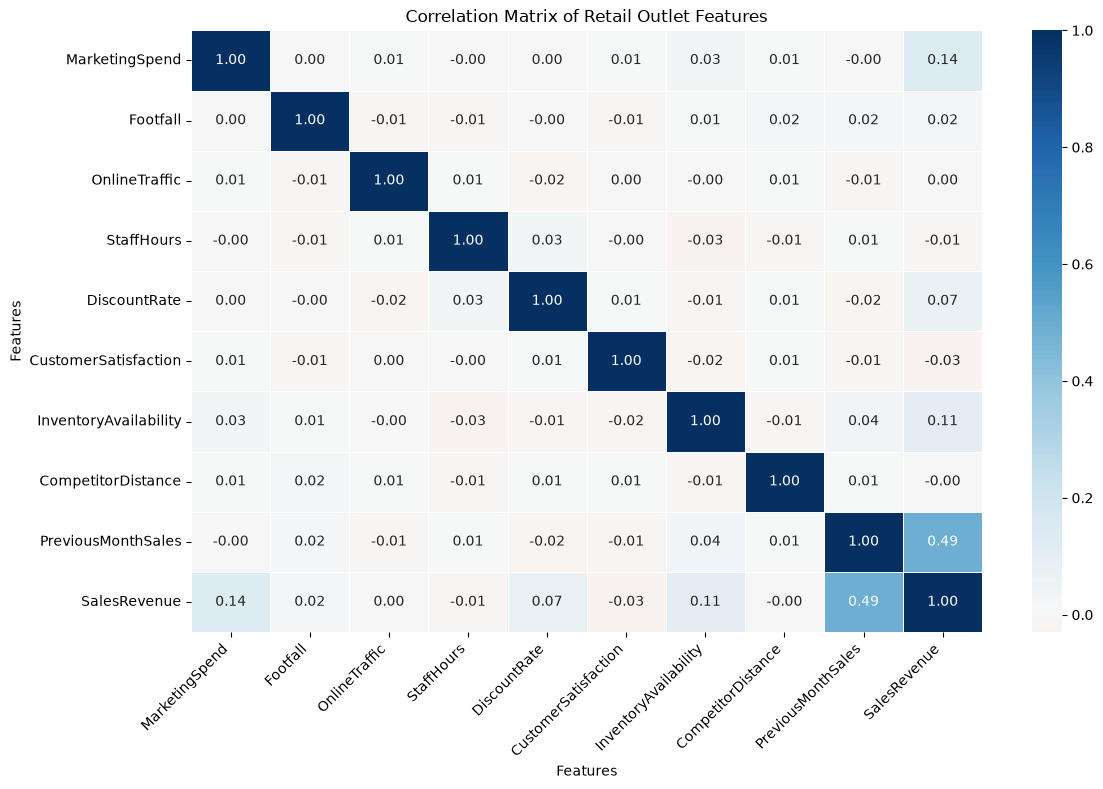

In [19]:
# Display the correlation results as a heatmap

# Create a heatmap of the correlations

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    center=0,
    linewidths=0.5,
)

plt.title("Correlation Matrix of Retail Outlet Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

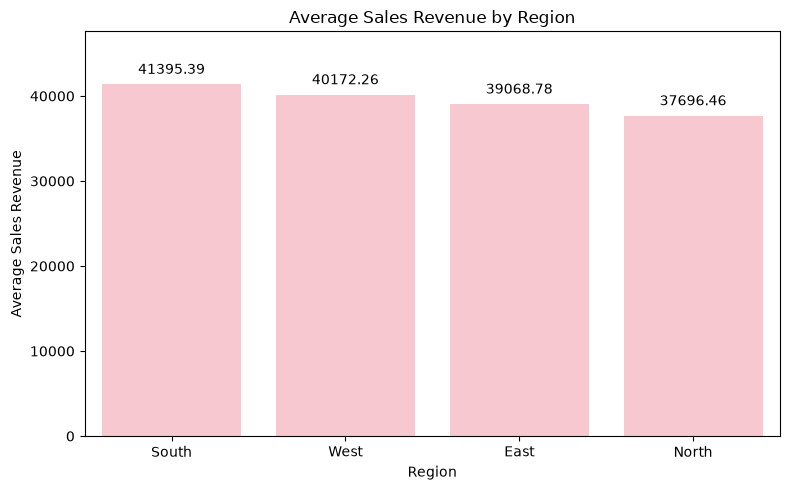

In [20]:
# Plot average sales revenue by region

# Calculate average sales by region

region_sales = (
    retail_outlets.groupby("Region", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
)

# Create the bar chart

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=region_sales,
    x="Region",
    y="SalesRevenue",
    order=region_sales["Region"],
    color="pink",
)

# Add value labels above the bars

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
    )

plt.title("Average Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales Revenue")
plt.ylim(0, region_sales["SalesRevenue"].max() * 1.15)
plt.tight_layout()
plt.show()

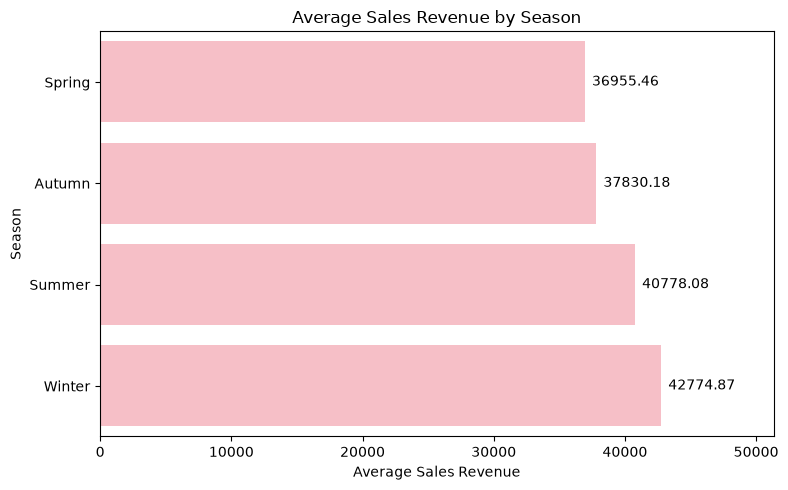

In [21]:
# Plot average sales revenue by season

# Calculate average sales by season

season_sales = (
    retail_outlets.groupby("Season", as_index=False)["SalesRevenue"]
    .mean()
    .sort_values("SalesRevenue", ascending=False)
)

# Create the horizontal bar chart

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=season_sales,
    x="SalesRevenue",
    y="Season",
    order=season_sales["Season"],
    color="lightpink",
)

# Add value labels

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_width():.2f}",
        (bar.get_width(), bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        xytext=(5, 0),
        textcoords="offset points",
    )

ax.invert_yaxis()
plt.title("Average Sales Revenue by Season")
plt.xlabel("Average Sales Revenue")
plt.ylabel("Season")
plt.xlim(0, season_sales["SalesRevenue"].max() * 1.20)
plt.tight_layout()
plt.show()

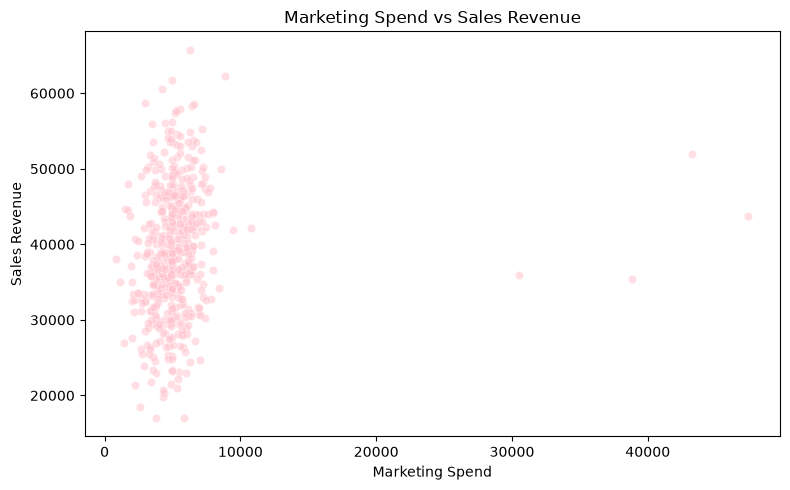

In [22]:
# Plot the relationship between marketing spend and sales revenue

# Create the scatter plot

plt.figure(figsize=(8, 5))
sample_data = retail_outlets.sample(n=500, random_state=42)

sns.scatterplot(
    data=sample_data,
    x="MarketingSpend",
    y="SalesRevenue",
    color="pink",
    alpha=0.5,
)

plt.title("Marketing Spend vs Sales Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Revenue")
plt.tight_layout()
plt.show()

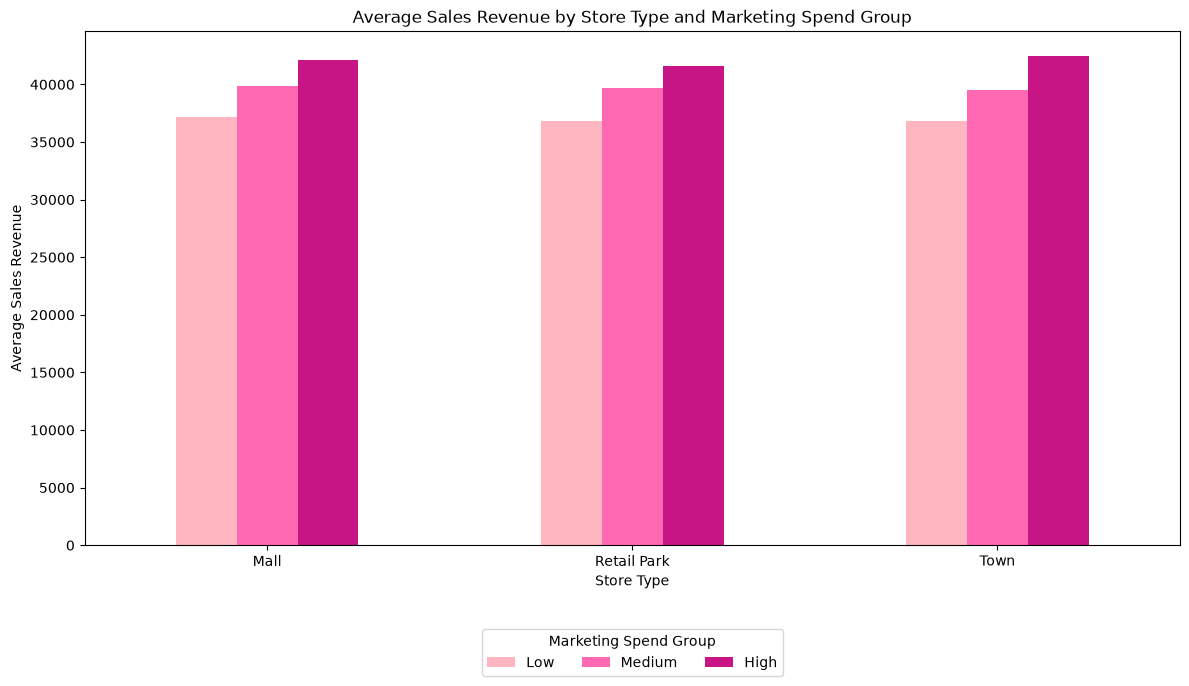

In [32]:

# Compare average sales revenue by store type and marketing spend group

ax = average_sales_by_store_and_spending.plot(
    kind="bar",
    figsize=(12, 7),
    color=["lightpink", "hotpink", "mediumvioletred"]
)

plt.title("Average Sales Revenue by Store Type and Marketing Spend Group")
plt.xlabel("Store Type")
plt.ylabel("Average Sales Revenue")
plt.xticks(rotation=0)

# Place the legend below the chart
plt.legend(
    title="Marketing Spend Group",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3
)

plt.tight_layout()
plt.show()


In [23]:
# Split the data into features and training and testing sets

from sklearn.model_selection import train_test_split

# Separate features and target

X = retail_outlets.drop(columns=["SalesRevenue", "StoreID", "SalesChange"])
y = retail_outlets["SalesRevenue"]

# Convert categorical columns to numeric columns

X = pd.get_dummies(X, drop_first=True)

# Split into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (4000, 21)
Testing features shape: (1000, 21)
Training target shape: (4000,)
Testing target shape: (1000,)


In [24]:
# Train a Linear Regression model and calculate its error scores

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train the model

model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions

y_pred = model.predict(X_test)

# Calculate metrics

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

# Display results

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")

MAE: 5006.95
RMSE: 6261.48
R²: 0.42


In [25]:
# Train a Random Forest model and calculate its error scores

from sklearn.ensemble import RandomForestRegressor

# Train the model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
)
rf_model.fit(X_train, y_train)

# Make predictions

rf_y_pred = rf_model.predict(X_test)

# Calculate metrics

rf_mae = mean_absolute_error(y_test, rf_y_pred)
rf_rmse = mean_squared_error(y_test, rf_y_pred) ** 0.5
rf_r2 = r2_score(y_test, rf_y_pred)

# Display results

print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²: {rf_r2:.2f}")

MAE: 5193.65
RMSE: 6463.18
R²: 0.39


In [26]:
# Linear Regression provides an interpretable baseline; Random Forest captures nonlinear relationships.
# Compare both models using the same test-set metrics

model_comparison = pd.DataFrame(
    {
        "Model": ["Linear Regression", "Random Forest"],
        "MAE": [mae, rf_mae],
        "RMSE": [rmse, rf_rmse],
        "R2": [r2, rf_r2],
    }
).sort_values("RMSE")

display(model_comparison.round(2))
best_model = model_comparison.iloc[0]["Model"]
print(f"Selected model based on the lowest RMSE: {best_model}")

,Model,MAE,RMSE,R2
0,Linear Regression,5006.95,6261.48,0.42
1,Random Forest,5193.65,6463.18,0.39


Selected model based on the lowest RMSE: Linear Regression


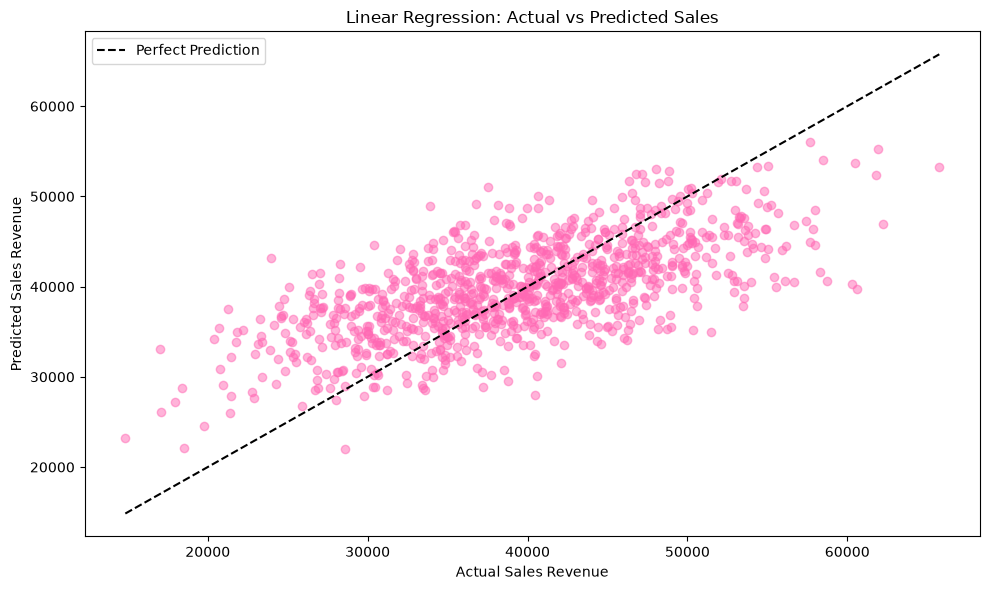

In [33]:

# Compare actual and predicted sales using Linear Regression

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, color="hotpink", alpha=0.5)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="black",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Linear Regression: Actual vs Predicted Sales")
plt.xlabel("Actual Sales Revenue")
plt.ylabel("Predicted Sales Revenue")
plt.legend()
plt.tight_layout()
plt.show()


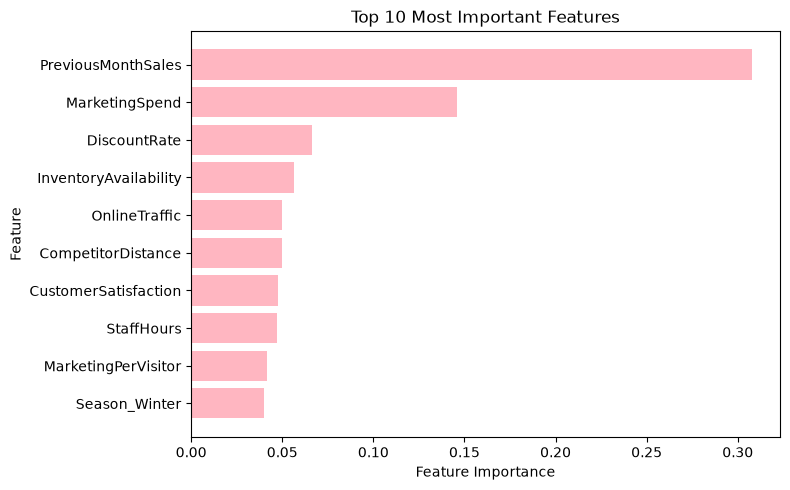

In [27]:
# Display the features with the greatest influence in the Random Forest

# Get the 10 most important features

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns,
).sort_values(ascending=False).head(10).sort_values()

# Create the horizontal bar chart

plt.figure(figsize=(8, 5))
plt.barh(feature_importance.index, feature_importance.values, color="lightpink")

plt.title("Top 10 Most Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()